# 01 — Training

Train `SmallCNN` on MNIST using Adam, track loss and accuracy on the validation set each epoch, and save the best checkpoint.

**Run all cells top-to-bottom.** Notebook 00 must have run first.

> **Kernel:** `source /root/LLM/venv/bin/activate && jupyter notebook --notebook-dir=image_nets/notebooks`

**What we do:** Imports, seeds, load config from notebook 00.
**Why:** Config carries batch size and seed — no hard-coding.
**What you should see:** Device and config printed.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path().resolve().parent))

import torch
import torch.nn as nn
import numpy as np
import json
import matplotlib.pyplot as plt
from torchvision import datasets, transforms

from tools.nets.cnn import SmallCNN
from tools.hardware.gpu import Timer, reset_memory_stats
from tools.observability.logger import JsonlLogger
from tools.viz.curves import plot_training_curves

FORCE_CPU = False
SEED      = 42
EPOCHS    = 8

torch.manual_seed(SEED)
np.random.seed(SEED)

NOTEBOOK_DIR  = pathlib.Path().resolve()
ARTIFACTS_DIR = NOTEBOOK_DIR.parent / "artifacts"
DATA_DIR      = ARTIFACTS_DIR / "mnist_data"

env    = json.loads((ARTIFACTS_DIR / "env.json").read_text())
config = json.loads((ARTIFACTS_DIR / "config.json").read_text())

device     = torch.device("cpu" if FORCE_CPU else env["device"])
N_CLASSES  = config["n_classes"]
VAL_FRAC   = config["val_frac"]
BATCH_SIZE = config["batch_size"]

print(f"device     : {device}")
print(f"epochs     : {EPOCHS}")
print(f"batch_size : {BATCH_SIZE}")

device     : cuda
epochs     : 8
batch_size : 128


**What we do:** Rebuild the exact same train/val/test split as notebook 00.
**Why:** The same seed and `random_split` call produces identical splits — no sample from val or test leaks into training.
**What you should see:** Split sizes matching notebook 00.

In [2]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,)),
])

train_full = datasets.MNIST(DATA_DIR, train=True,  download=False, transform=transform)
test_set   = datasets.MNIST(DATA_DIR, train=False, download=False, transform=transform)

n_val   = int(len(train_full) * VAL_FRAC)
n_train = len(train_full) - n_val
rng     = torch.Generator().manual_seed(SEED)
train_set, val_set = torch.utils.data.random_split(
    train_full, [n_train, n_val], generator=rng
)

train_loader = torch.utils.data.DataLoader(
    train_set, batch_size=BATCH_SIZE, shuffle=True,
    generator=torch.Generator().manual_seed(SEED)
)
val_loader   = torch.utils.data.DataLoader(val_set,  batch_size=512, shuffle=False)
test_loader  = torch.utils.data.DataLoader(test_set, batch_size=512, shuffle=False)

print(f"train  : {len(train_set):>6,}  ({len(train_loader)} batches)")
print(f"val    : {len(val_set):>6,}")
print(f"test   : {len(test_set):>6,}  (held out — not touched here)")

assert len(train_set) == 54000, "FAIL: train size"
print("PASS: data loaders ready")

train  : 54,000  (422 batches)
val    :  6,000
test   : 10,000  (held out — not touched here)
PASS: data loaders ready


**What we do:** Define the model, loss, and Adam optimizer.
**Why:** Adam adapts the learning rate per parameter — standard choice for CNNs. CrossEntropy combines log-softmax + NLL in one stable operation.
**What you should see:** Parameter count matching notebook 00.

In [3]:
torch.manual_seed(SEED)
model     = SmallCNN(N_CLASSES).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

n_params = sum(p.numel() for p in model.parameters())
print(f"Parameters : {n_params:,}")
print(f"Loss       : CrossEntropyLoss")
print(f"Optimizer  : Adam  lr=1e-3")

assert n_params == config["n_params"],     f"FAIL: param count mismatch {n_params} vs {config['n_params']}"
print("PASS: model ready")

Parameters : 206,922
Loss       : CrossEntropyLoss
Optimizer  : Adam  lr=1e-3
PASS: model ready


**What we do:** Run the training loop for `EPOCHS` epochs. After each epoch evaluate on the val set and save the checkpoint if val accuracy improved.
**Why:** Saving the *best* checkpoint (not the last) guards against overfitting in later epochs.
**What you should see:** Loss falling and accuracy rising each epoch; final val accuracy should be > 98 %.

In [4]:
logger   = JsonlLogger(ARTIFACTS_DIR / "training_log.jsonl")
best_acc = 0.0
history  = []

reset_memory_stats(device)

for epoch in range(1, EPOCHS + 1):
    # ── training ──────────────────────────────────────────────────────────────
    model.train()
    tr_loss = tr_correct = tr_total = 0
    with Timer() as t_epoch:
        for X, y in train_loader:
            X, y = X.to(device), y.to(device)
            optimizer.zero_grad()
            out  = model(X)
            loss = criterion(out, y)
            loss.backward()
            optimizer.step()
            tr_loss    += loss.item() * len(y)
            tr_correct += (out.argmax(1) == y).sum().item()
            tr_total   += len(y)

    tr_loss /= tr_total
    tr_acc   = tr_correct / tr_total

    # ── validation ────────────────────────────────────────────────────────────
    model.eval()
    vl_loss = vl_correct = vl_total = 0
    with torch.no_grad():
        for X, y in val_loader:
            X, y = X.to(device), y.to(device)
            out      = model(X)
            vl_loss += criterion(out, y).item() * len(y)
            vl_correct += (out.argmax(1) == y).sum().item()
            vl_total   += len(y)
    vl_loss /= vl_total
    vl_acc   = vl_correct / vl_total

    # ── checkpoint ────────────────────────────────────────────────────────────
    if vl_acc > best_acc:
        best_acc = vl_acc
        torch.save({"model_state": model.state_dict(),
                    "n_classes"  : N_CLASSES,
                    "epoch"      : epoch}, ARTIFACTS_DIR / "best_model.pt")
        tag = " ← best"
    else:
        tag = ""

    row = {"epoch": epoch, "train_loss": round(tr_loss, 5),
           "val_loss": round(vl_loss, 5),
           "train_acc": round(tr_acc, 4), "val_acc": round(vl_acc, 4)}
    history.append(row); logger.log(row)
    print(f"epoch {epoch}/{EPOCHS}  "
          f"tr_loss={tr_loss:.4f}  tr_acc={tr_acc:.4f}  "
          f"vl_loss={vl_loss:.4f}  vl_acc={vl_acc:.4f}  "
          f"({t_epoch.s:.1f}s){tag}")

print(f"\nBest val acc : {best_acc:.4f}")

epoch 1/8  tr_loss=0.2343  tr_acc=0.9297  vl_loss=0.0802  vl_acc=0.9765  (7.3s) ← best


epoch 2/8  tr_loss=0.0640  tr_acc=0.9805  vl_loss=0.0678  vl_acc=0.9808  (5.9s) ← best


epoch 3/8  tr_loss=0.0426  tr_acc=0.9870  vl_loss=0.0461  vl_acc=0.9858  (6.9s) ← best


epoch 4/8  tr_loss=0.0333  tr_acc=0.9897  vl_loss=0.0506  vl_acc=0.9848  (7.5s)


epoch 5/8  tr_loss=0.0267  tr_acc=0.9916  vl_loss=0.0464  vl_acc=0.9887  (6.9s) ← best


epoch 6/8  tr_loss=0.0200  tr_acc=0.9937  vl_loss=0.0437  vl_acc=0.9873  (7.0s)


epoch 7/8  tr_loss=0.0168  tr_acc=0.9948  vl_loss=0.0485  vl_acc=0.9883  (6.9s)


epoch 8/8  tr_loss=0.0136  tr_acc=0.9957  vl_loss=0.0398  vl_acc=0.9895  (7.0s) ← best

Best val acc : 0.9895


**What we do:** Plot training and validation loss / accuracy curves.
**Why:** The gap between train and val curves shows whether the model is overfitting. Diverging curves → reduce capacity or add regularisation.
**What you should see:** Both curves converging, val lagging train slightly.

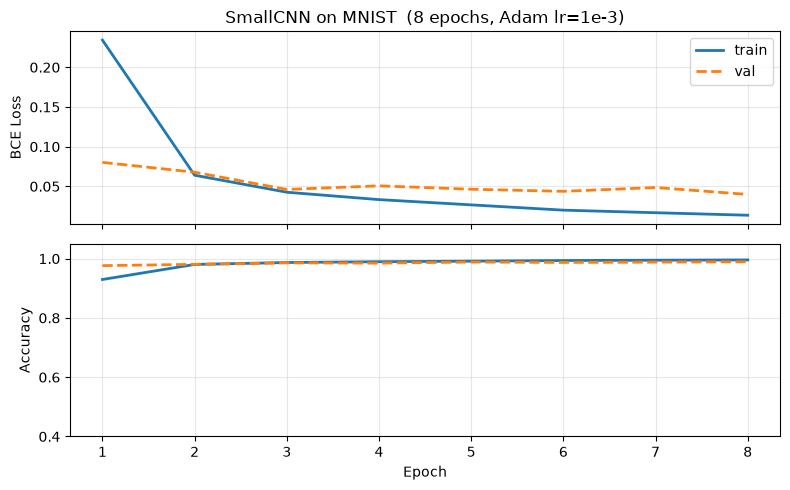

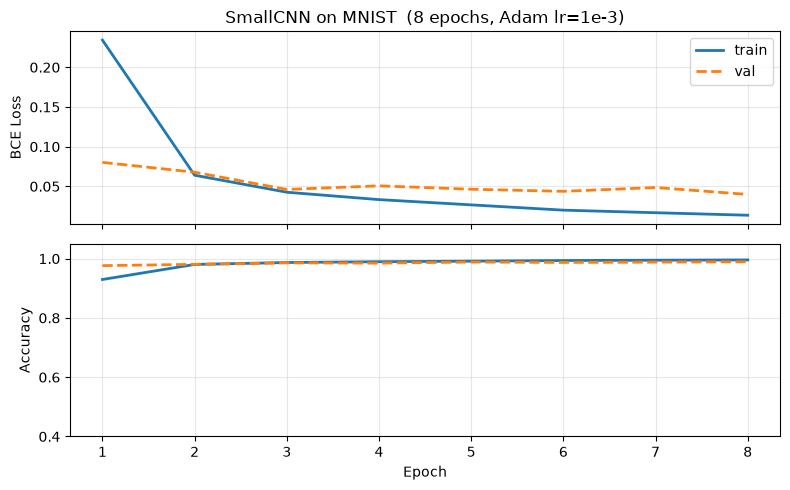

In [5]:
plot_training_curves(
    history,
    save_path=ARTIFACTS_DIR / "training_curves.png",
    title=f"SmallCNN on MNIST  ({EPOCHS} epochs, Adam lr=1e-3)",
)

**What we do:** Report GPU peak memory used during training.
**Why:** MNIST + SmallCNN is tiny; this baseline will matter when we scale to larger datasets.
**What you should see:** A few MB — well within the 4 GB VRAM.

In [6]:
if device.type == "cuda":
    peak_mb = torch.cuda.max_memory_allocated(device) / 1e6
    print(f"GPU peak memory : {peak_mb:.1f} MB")
else:
    print("CPU run — no GPU memory stats.")

assert best_acc > 0.97, f"FAIL: best val acc {best_acc:.4f} < 0.97"
print(f"PASS: val acc {best_acc:.4f} > 0.97")

GPU peak memory : 73.4 MB
PASS: val acc 0.9895 > 0.97


**What we do:** Score the test set exactly once using the best checkpoint.
**Why:** The test set is touched only once, at the end of the training notebook, before any visualisation or experimentation.
**What you should see:** Test accuracy > 98 %.

In [7]:
ckpt = torch.load(ARTIFACTS_DIR / "best_model.pt",
                  map_location=device, weights_only=False)
model_best = SmallCNN(N_CLASSES).to(device)
model_best.load_state_dict(ckpt["model_state"])
model_best.eval()

te_correct = te_total = 0
with torch.no_grad():
    for X, y in test_loader:
        X, y = X.to(device), y.to(device)
        preds = model_best(X).argmax(1)
        te_correct += (preds == y).sum().item()
        te_total   += len(y)

test_acc = te_correct / te_total
print(f"Test accuracy : {test_acc:.4f}  ({te_correct}/{te_total})")

assert test_acc > 0.98, f"FAIL: test acc {test_acc:.4f} < 0.98"
print("PASS: test accuracy > 98 %")

Test accuracy : 0.9900  (9900/10000)
PASS: test accuracy > 98 %
